# Anisotropy field (Hk) by the area method + shape anisotropy

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------- inputs ----------------
FILE_IP  = "979D_Fe_GroupC_IP.csv"       # in-plane loop   (Field G, Moment emu)
FILE_OOP = "979D_Fe_GroupC - Copy.csv"   # out-of-plane loop

L1_mm, L2_mm, t_nm = 6.68, 6.37, 13.65  # sample size and thickness
A = (L1_mm/10)*(L2_mm/10)               # cm^2
t = t_nm*1e-7                           # cm
V = A*t                                 # cm^3

H_FIT    = 6000    # G : fit the diamagnetic slope for |H| above this
SAT_FRAC = 0.85    # fraction of H_max above which M is taken as saturated
BRANCH   = "ascending"   # positive-field branch: "ascending" or "descending"
PASS     = "first"       # if several passes exist: "first" or "longest"
MS_MODE  = "each"        # integrate each curve up to its own saturation ("each")
                         # or up to the mean Ms of both curves ("common")

print(f"A = {A:.4f} cm^2, t = {t:.3e} cm, V = {V:.4e} cm^3")

A = 0.4255 cm^2, t = 1.365e-06 cm, V = 5.8083e-07 cm^3


In [2]:
def load_vsm(path):
    # read Field, Moment; skips header/unit rows
    H, M = [], []
    with open(path, encoding="utf-8-sig") as f:
        for line in f:
            p = line.replace("\t", ",").replace(";", ",").strip().split(",")
            try:
                H.append(float(p[0])); M.append(float(p[1]))
            except (ValueError, IndexError):
                continue
    return np.array(H), np.array(M)

def trap(y, x):
    return float(np.sum((y[1:] + y[:-1]) * np.diff(x)) / 2)

def remove_diamagnetic(H, m, h_fit=H_FIT):
    # fit m = a + chi*H on the positive-field branch for H > h_fit, subtract only chi*H
    sel = H > h_fit
    chi, a = np.polyfit(H[sel], m[sel], 1)
    return m - chi*H, chi

def positive_branch(H, M, mode=BRANCH, which=PASS, min_len=10):
    step = np.diff(H)
    direction = np.r_[step[0], step]
    ok = (H >= 0) & (direction > 0 if mode == "ascending" else direction < 0)
    idx = np.flatnonzero(ok)
    groups = [g for g in np.split(idx, np.flatnonzero(np.diff(idx) != 1) + 1) if len(g) >= min_len]
    g = groups[0] if which == "first" else max(groups, key=len)
    order = np.argsort(H[g])
    return H[g][order], M[g][order]

def prepare(path):
    H, m = load_vsm(path)
    Hb, mb = positive_branch(H, m)               # step 3: positive-field branch
    mb, chi = remove_diamagnetic(Hb, mb)         # step 2: diamagnetic slope
    Mb = mb / V                                  # step 3: M = m/(A t), emu/cm^3
    return dict(H=Hb, M=Mb, chi=chi, Hmax=Hb.max())

ip, oop = prepare(FILE_IP), prepare(FILE_OOP)
for n, d in (("In-plane", ip), ("Out-of-plane", oop)):
    print(f"{n:13s}: diamagnetic slope = {d['chi']:.3e} emu/G, branch points = {len(d['H'])}, H up to {d['H'].max():.0f} G")

In-plane     : diamagnetic slope = -1.402e-09 emu/G, branch points = 292, H up to 9953 G
Out-of-plane : diamagnetic slope = 1.919e-08 emu/G, branch points = 202, H up to 9982 G


In [3]:
# Ms from the saturated part of both curves
def m_sat(d):
    return d["M"][d["H"] > SAT_FRAC*d["Hmax"]].mean()

Ms_ip, Ms_oop = m_sat(ip), m_sat(oop)
Ms = 0.5*(Ms_ip + Ms_oop)
print(f"Ms (in-plane curve)     = {Ms_ip:.0f} emu/cm^3")
print(f"Ms (out-of-plane curve) = {Ms_oop:.0f} emu/cm^3")
print(f"Ms used (mean)          = {Ms:.0f} emu/cm^3 = {Ms:.0f} kA/m")

mismatch = abs(Ms_ip - Ms_oop)/Ms
print(f"Ms mismatch between the two curves = {100*mismatch:.1f} %"
      + ("  <- large: check A, t, background slope and alignment" if mismatch > 0.05 else ""))

# step 4: E = integral of H dM from 0 to Ms  ==  area between curve and M = Ms
def energy(d, Ms_top):
    return trap(Ms_top - np.minimum(d["M"], Ms_top), d["H"])   # erg/cm^3 (Oe * emu/cm^3)

top_ip  = Ms_ip  if MS_MODE == "each" else Ms
top_oop = Ms_oop if MS_MODE == "each" else Ms
E_ip, E_oop = energy(ip, top_ip), energy(oop, top_oop)
print(f"Integration limit mode: {MS_MODE}")
print(f"\nE (in-plane)     = {E_ip:.3e} erg/cm^3")
print(f"E (out-of-plane) = {E_oop:.3e} erg/cm^3")

Ms (in-plane curve)     = 440 emu/cm^3
Ms (out-of-plane curve) = 1465 emu/cm^3
Ms used (mean)          = 952 emu/cm^3 = 952 kA/m
Ms mismatch between the two curves = 107.7 %  <- large: check A, t, background slope and alignment
Integration limit mode: each

E (in-plane)     = 3.102e+05 erg/cm^3
E (out-of-plane) = 1.797e+06 erg/cm^3


In [4]:
# step 5-6: Keff and Hk  (hard axis = larger energy)
if E_oop >= E_ip:
    hard, easy, E_hard, E_easy = "Out-of-plane", "In-plane", E_oop, E_ip
else:
    hard, easy, E_hard, E_easy = "In-plane", "Out-of-plane", E_ip, E_oop
print(f"Easy axis = {easy}, hard axis = {hard}")

K_eff = E_hard - E_easy                 # erg/cm^3
Hk    = 2*K_eff/Ms                      # Oe (= G)
print(f"\nK_eff = {K_eff:.3e} erg/cm^3 = {K_eff*0.1:.3e} J/m^3")
print(f"Hk    = {Hk:.0f} Oe = {Hk/1e4:.3f} T (mu0*Hk)")

# shape anisotropy
mu0 = 4e-7*np.pi
Ms_SI = Ms*1e3                          # A/m
K_shape_SI  = 0.5*mu0*Ms_SI**2          # J/m^3
K_shape_cgs = 2*np.pi*Ms**2             # erg/cm^3
Hk_shape    = 4*np.pi*Ms                # Oe  (= 2*K_shape/Ms)
print(f"\nK_shape = 1/2 mu0 Ms^2 = {K_shape_SI:.3e} J/m^3 = {K_shape_cgs:.3e} erg/cm^3")
print(f"Hk_shape = 4*pi*Ms = {Hk_shape:.0f} Oe = {Hk_shape/1e4:.3f} T")

# comparison: measured Keff vs shape anisotropy
Ku = K_shape_cgs - K_eff
print(f"\nK_eff / K_shape = {K_eff/K_shape_cgs:.2f}")
print(f"Non-shape (intrinsic + interface) contribution K_shape - K_eff = {Ku:.3e} erg/cm^3 "
      f"({'favours the plane less than shape alone' if Ku > 0 else 'extra in-plane contribution'})")

Easy axis = In-plane, hard axis = Out-of-plane

K_eff = 1.487e+06 erg/cm^3 = 1.487e+05 J/m^3
Hk    = 3122 Oe = 0.312 T (mu0*Hk)

K_shape = 1/2 mu0 Ms^2 = 5.698e+05 J/m^3 = 5.698e+06 erg/cm^3
Hk_shape = 4*pi*Ms = 11967 Oe = 1.197 T

K_eff / K_shape = 0.26
Non-shape (intrinsic + interface) contribution K_shape - K_eff = 4.211e+06 erg/cm^3 (favours the plane less than shape alone)


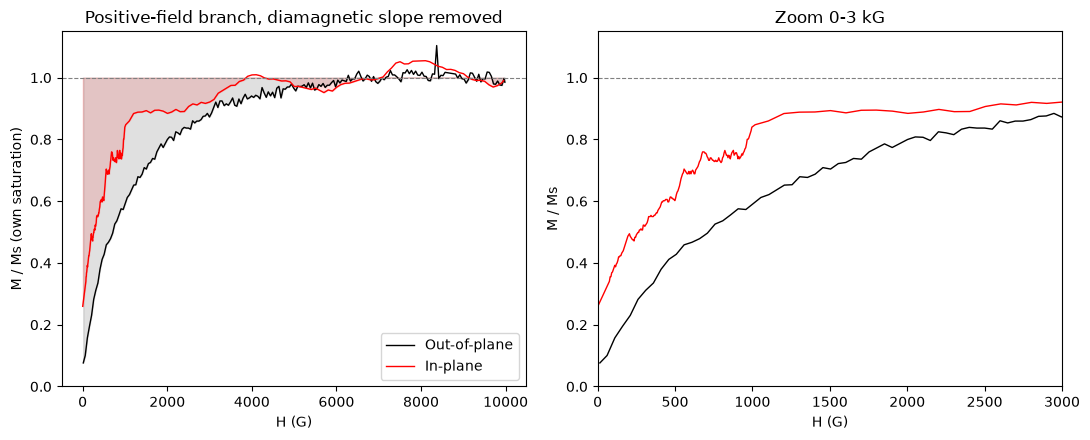

In [5]:
# plot: area between each curve and M = Ms (the shaded area of the slide)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for d, c, lab, top in ((oop, "k", "Out-of-plane", top_oop), (ip, "r", "In-plane", top_ip)):
    ax[0].plot(d["H"], d["M"]/top, color=c, lw=1, label=lab)
    ax[0].fill_between(d["H"], np.minimum(d["M"], top)/top, 1, color=c, alpha=0.12)
ax[0].axhline(1, color="gray", ls="--", lw=0.8)
ax[0].set_xlabel("H (G)"); ax[0].set_ylabel("M / Ms (own saturation)" if MS_MODE == "each" else "M / Ms"); ax[0].set_ylim(0, 1.15)
ax[0].set_title("Positive-field branch, diamagnetic slope removed"); ax[0].legend()

ax[1].plot(oop["H"], oop["M"]/top_oop, "k", lw=1); ax[1].plot(ip["H"], ip["M"]/top_ip, "r", lw=1)
ax[1].axhline(1, color="gray", ls="--", lw=0.8)
ax[1].set_xlim(0, 3000); ax[1].set_ylim(0, 1.15)
ax[1].set_xlabel("H (G)"); ax[1].set_ylabel("M / Ms"); ax[1].set_title("Zoom 0-3 kG")
plt.tight_layout(); plt.savefig("anisotropy_area_method.png", dpi=150); plt.show()